In [55]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.my_uoro import UORO

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
device = 'cuda:0'
# model = create_agent(cf, device)
# memories = create_memories(model.actor, cf.num_envs, device=device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# model.train()
# 1
model = UOROModel(3, 10, 3, 1e-3, device)
model.initialize_state(device)

using GRU


In [3]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=1, l=4, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [73]:
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=10
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,10,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss)
        loss_acc += loss
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

In [90]:
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=2
cf.query_dim=4
cf.nb_latents=2
cf.latent_dim_head=2
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
old_s = rearrange(old_s, 'b d l h -> (b d l h)')
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [93]:
print(uoro_grad.theta_tilda.shape)

torch.Size([2137])


In [94]:
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

tensor(46.7007, device='cuda:0', grad_fn=<AddBackward0>)


tensor(112.7740, device='cuda:0', grad_fn=<AddBackward0>)
tensor(111.7048, device='cuda:0', grad_fn=<AddBackward0>)
tensor(110.2989, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.6764, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.4023, device='cuda:0', grad_fn=<AddBackward0>)
tensor(110.1904, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.8392, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.8347, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.0656, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.1920, device='cuda:0', grad_fn=<AddBackward0>)
tensor(108.9115, device='cuda:0', grad_fn=<AddBackward0>)
tensor(108.8537, device='cuda:0', grad_fn=<AddBackward0>)
tensor(108.8427, device='cuda:0', grad_fn=<AddBackward0>)
tensor(108.7706, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.3259, device='cuda:0', grad_fn=<AddBackward0>)
tensor(111.2244, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.7449, device='cuda:0', grad_fn=<AddBackward0>)
tensor(109.140

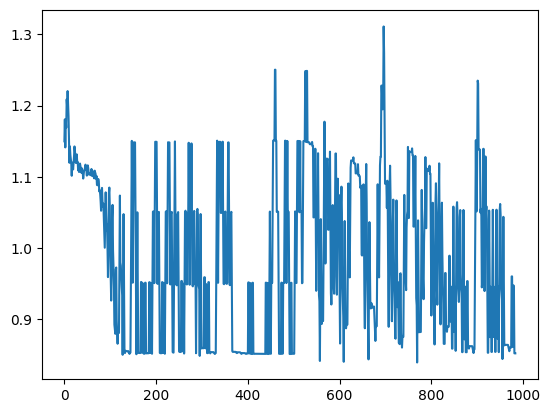

In [39]:
# plt.plot(loss_all)
h=10
plt.plot([sum(loss_all[i: i+h])/h for i in range(int(len(loss_all)/h))])
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)